1. Import library

In [1]:

import requests
import folium
import geopandas as gpd
from shapely.geometry import shape
from pyproj import CRS
import json
import os
import pandas as pd

2. Pengambilan Data GeoJSON dari API MapID

In [2]:
urls = {
"tingkat_polusi":
'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984a42396de9425652debb4&project_id=697e526a949d92a51f0b4816',
 "harga_lahan": 'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984a994bbaa47f3ce684277&project_id=697e526a949d92a51f0b4816',
 "fasilitas_transportasi":
'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984aa4296de9425652ebfad&project_id=697e526a949d92a51f0b4816',
 "fasilitas_pendidikan":
'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984ac32bbaa47f3ce68c2f2&project_id=697e526a949d92a51f0b4816',
 "luas_lahan": 'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984ac502d33abfe646477d1&project_id=697e526a949d92a51f0b4816',
 "ketersediaan_air_bersih":
'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984ac7abbaa47f3ce68c40d&project_id=697e526a949d92a51f0b4816',
 "risiko_banjir": 'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984ac9dbbaa47f3ce68dc4d&project_id=697e526a949d92a51f0b4816',
 "kepadatan_penduduk":
'https://geoserver.mapid.io/layers_new/get_layer?api_key=70b6758f25e94e6a849a32d935bce369&layer_id=6984acd196de9425652f4015&project_id=697e526a949d92a51f0b4816'
}

3. Membaca & Mengonversi Data GeoJSON ke GeoDataFrame

In [3]:
import geopandas as gpd
def get_gdf_from_api(url):
 response = requests.get(url)
 if response.status_code == 200:
   geojson = response.json()
   gdf = gpd.GeoDataFrame.from_features(geojson['features'])
   print(f"Berhasil mengambil data dari {url.split('&layer_id=')[1][:10]}...")
   return gdf
 else:
   print(f"Gagal mengambil data dari {url}")
 return gpd.GeoDataFrame()
# Membaca semua data ke dalam dictionary GeoDataFrame
gdfs = {}
for key, url in urls.items():
 gdfs[key] = get_gdf_from_api(url)

Berhasil mengambil data dari 6984a42396...
Berhasil mengambil data dari 6984a994bb...
Berhasil mengambil data dari 6984aa4296...
Berhasil mengambil data dari 6984ac32bb...
Berhasil mengambil data dari 6984ac502d...
Berhasil mengambil data dari 6984ac7abb...
Berhasil mengambil data dari 6984ac9dbb...
Berhasil mengambil data dari 6984acd196...


4. Pemeriksaan & Penyesuaian Data (Null & CRS)

In [4]:
from pyproj import CRS
for key, gdf in gdfs.items():
 # Isi null dengan default (0 atau 'TIDAK DIKETAHUI')
 for col in gdf.columns:
   if gdf[col].dtype == 'O':
    gdf[col] = gdf[col].fillna('TIDAK DIKETAHUI')
 else:
   gdf[col] = gdf[col].fillna(0)
 # Set CRS ke EPSG:4326 jika belum
 if gdf.crs is None or gdf.crs.to_epsg() != 4326:
   gdf.set_crs(epsg=4326, inplace=True)
   gdfs[key] = gdf
print("Semua data sudah dicek dan disesuaikan.")

Semua data sudah dicek dan disesuaikan.


5. Visualisasi Data Spasial Setiap Variabel

In [5]:
import folium
for key, gdf in gdfs.items():
 m = folium.Map(location=[-6.23, 106.83], zoom_start=13)
 folium.GeoJson(gdf).add_to(m)
 folium.LayerControl().add_to(m)
 display(m)
 print(f"Peta untuk variabel: {key}")

Peta untuk variabel: tingkat_polusi


Peta untuk variabel: harga_lahan


Peta untuk variabel: fasilitas_transportasi


Peta untuk variabel: fasilitas_pendidikan


Peta untuk variabel: luas_lahan


Peta untuk variabel: ketersediaan_air_bersih


Peta untuk variabel: risiko_banjir


Peta untuk variabel: kepadatan_penduduk


6. Overlay/Intersect Data Spasial Multi-Variabel

Jumlah area hasil intersect: 5
Kolom hasil intersect: Index(['KEPADATAN', 'RISIKO_BANJIR', 'AIR_BERSIH', 'LUAS_LAHAN',
       'DEKAT_PENDIDIKAN', 'DEKAT_TRANSPORTASI', 'HARGA_LAHAN',
       'TINGKAT_POLUSI', 'geometry'],
      dtype='object')


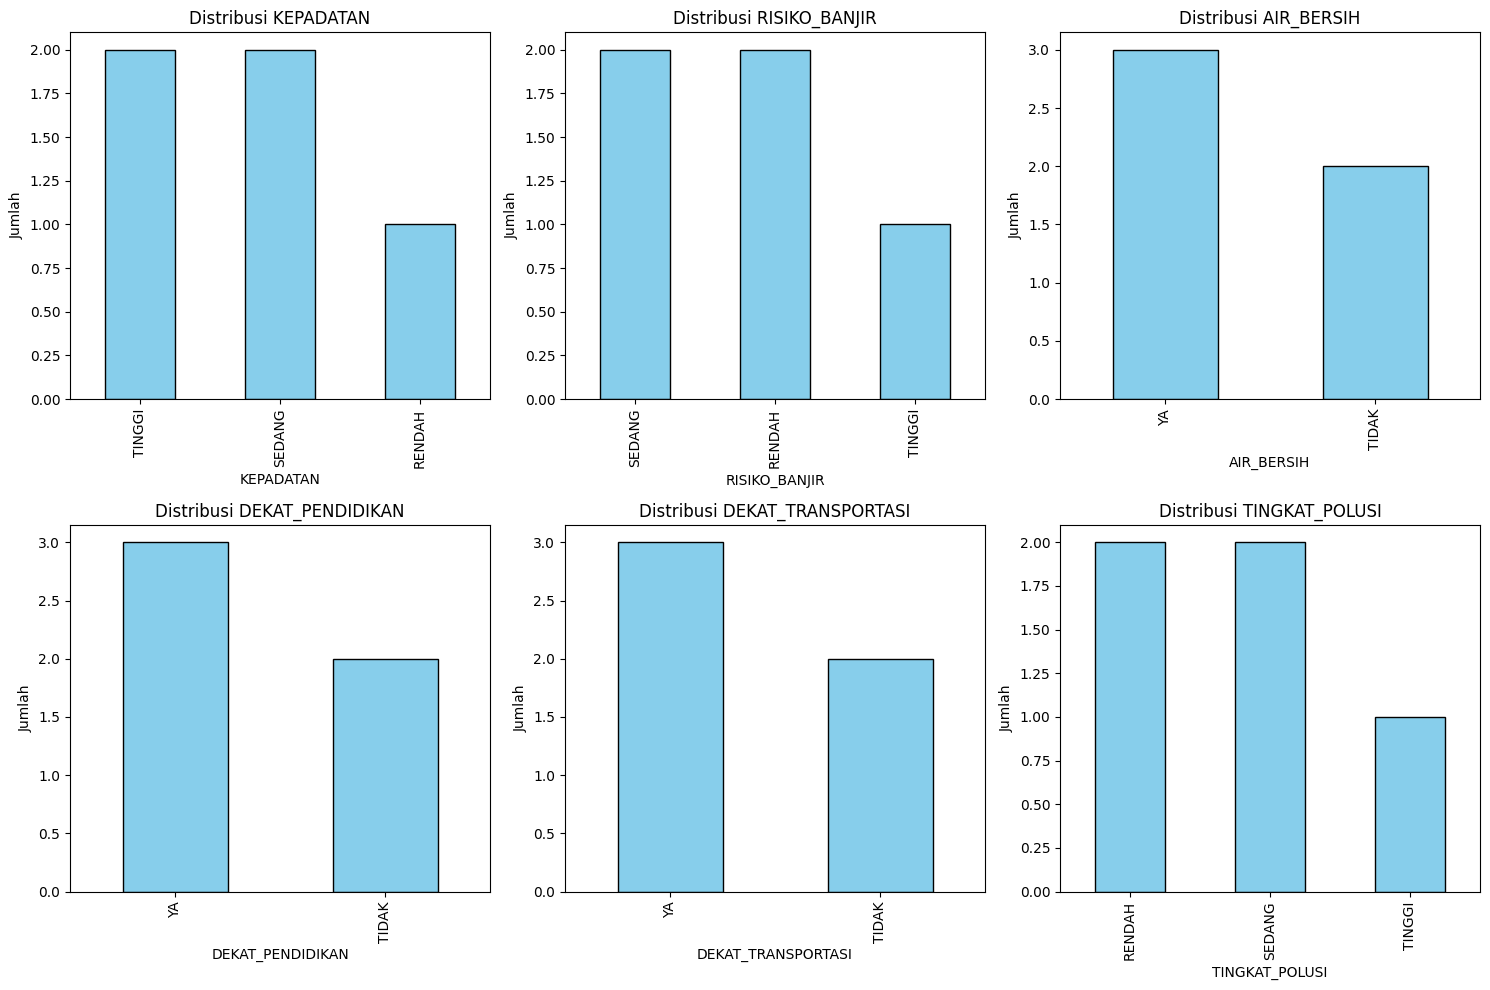

In [6]:
import geopandas as gpd
from pandas.core.api import Index
# Pastikan kolom 'ID' dihapus/rename agar tidak error saat overlay
for key in gdfs.keys():
 if 'ID' in gdfs[key].columns:
   gdfs[key] = gdfs[key].drop(columns=['ID'])
# List GeoDataFrame yang akan di-intersect (urutkan sesuai kebutuhan analisis)
gdf_list = [
 gdfs['kepadatan_penduduk'],
 gdfs['risiko_banjir'],
 gdfs['ketersediaan_air_bersih'],
 gdfs['luas_lahan'],
 gdfs['fasilitas_pendidikan'],
 gdfs['fasilitas_transportasi'],
 gdfs['harga_lahan'],
 gdfs['tingkat_polusi']
]
# Fungsi overlay/intersect berurutan
def overlay_multiple(gdf_list):
 result = gdf_list[0]
 for gdf in gdf_list[1:]:
   if not gdf.empty:
    result = gpd.overlay(result, gdf, how='intersection')
    result = result[result.is_valid]
 return result
gdf_intersect = overlay_multiple(gdf_list)
print(f"Jumlah area hasil intersect: {len(gdf_intersect)}")

print("Kolom hasil intersect:", gdf_intersect.columns)
import matplotlib.pyplot as plt
kategori_cols = [
 'KEPADATAN', 'RISIKO_BANJIR', 'AIR_BERSIH',
 'DEKAT_PENDIDIKAN', 'DEKAT_TRANSPORTASI', 'TINGKAT_POLUSI'
]
plt.figure(figsize=(15, 10))
for i, col in enumerate(kategori_cols, 1):
 if col in gdf_intersect.columns:
   plt.subplot(2, 3, i)
   gdf_intersect[col].value_counts().plot(kind='bar',
color='skyblue', edgecolor='black')
 plt.title(f'Distribusi {col}')
 plt.xlabel(col)
 plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

6.2 

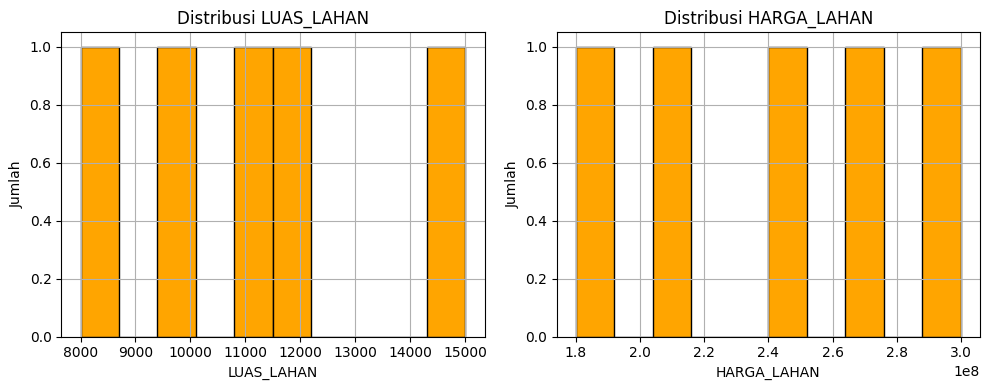

In [7]:
numerik_cols = []
if 'LUAS_LAHAN' in gdf_intersect.columns:
 numerik_cols.append('LUAS_LAHAN')
if 'HARGA_LAHAN' in gdf_intersect.columns:
 numerik_cols.append('HARGA_LAHAN')
plt.figure(figsize=(10, 4))
for i, col in enumerate(numerik_cols, 1):
 plt.subplot(1, len(numerik_cols), i)
 gdf_intersect[col].hist(bins=10, color='orange',
edgecolor='black')
 plt.title(f'Distribusi {col}')
 plt.xlabel(col)
 plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

7. Skoring & Klasifikasi Kesesuaian Lokasi

In [8]:
def skoring(row):
  skor = 0
  #Skoring kepadatan
  skor += {"RENDAH": 1, "SEDANG": 2, "TINGGI": 3}.get(str(row.get("KEPADATAN", "")).upper(), 0)
  #Skoring risiko banjir
  skor += {"RENDAH": 1, "SEDANG": 2, "TINGGI": 1}.get(str(row.get("RISIKO_BANJIR", "")).upper(), 0)
  #Skoring air bersih
  skor += 3 if str(row.get("AIR_BERSIH", "")).upper() == "YA" else 1
  #Skoring luas lahan
  luas = row.get("LUAS_LAHAN", 0)
  skor += 3 if luas > 10000 else 2 if luas > 5000 else 1
  #Skoring fasilitas pendidikan
  skor += 2 if str(row.get("DEKAT_PENDIDIKAN", "")).upper() == "YA" else 1
  #Skoring fasilitas transportasi
  skor += 2 if str(row.get("DEKAT_TRANSPORTASI", "")).upper() == "YA" else 1
  #Skoring harga lahan
  harga = row.get("HARGA_LAHAN", 0)
  skor += 3 if harga < 200000000 else 2 if harga < 275000000 else 1
  #Skoring tingkat polusi
  skor += {"RENDAH": 3, "SEDANG": 2, "TINGGI": 1}.get(str(row.get("TINGKAT_POLUSI", "")).upper(), 0)
  return skor

# Hitung skor total untuk setiap baris
gdf_intersect['SKOR_TOTAL'] = gdf_intersect.apply(skoring, axis=1)
# Klasifikasi kesesuaian lokasi
gdf_intersect['KESESUAIAN'] = pd.cut(
 gdf_intersect['SKOR_TOTAL'],
 bins=[0, 10, 16, 24], # Interval: 0-10=RENDAH, 11-16=SEDANG, 17-24=TINGGI
 labels=['RENDAH', 'SEDANG', 'TINGGI'],
 include_lowest=True
)
# Lihat hasil 10 baris pertama
print(gdf_intersect[['SKOR_TOTAL', 'KESESUAIAN']].head(10))

   SKOR_TOTAL KESESUAIAN
0          15     SEDANG
1          16     SEDANG
2          15     SEDANG
3          14     SEDANG
4          18     TINGGI


8. Visualisasi Hasil Skoring & Kesesuaian Lokasi

In [9]:
import folium
import branca.colormap as cm
# Mapping label ke warna
label_to_color = {'RENDAH': 'red', 'SEDANG': 'orange', 'TINGGI':
'green'}
# Fungsi style untuk seluruh GeoDataFrame
def style_function(feature):
 kategori = feature['properties'].get('KESESUAIAN', 'gray')
 return {
 'fillColor': label_to_color.get(kategori, 'gray'),
 'color': 'black',
 'weight': 1,
 'fillOpacity': 0.5
 }
# Buat peta
m = folium.Map(location=[-6.23, 106.83], zoom_start=13)

# Tambahkan seluruh GeoDataFrame sekaligus
folium.GeoJson(
 gdf_intersect,
 style_function=style_function,
 tooltip=folium.GeoJsonTooltip(fields=['SKOR_TOTAL', 'KESESUAIAN'])
).add_to(m)
# Colormap manual (opsional)
colormap = cm.StepColormap(
 colors=['red', 'orange', 'green'],
 vmin=0, vmax=2,
 index=[0, 1, 2, 3],
 caption='Kesesuaian Lokasi'
)
colormap.add_to(m)
m

9. Menyimpan Hasil Analisis ke File GeoJSON

In [10]:
import os
output_dir = "."
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir,
"hasil_analisis_lokasi.geojson")
gdf_intersect.to_file(output_path, driver='GeoJSON')
print(f"Hasil analisis berhasil disimpan di: {output_path}")

Hasil analisis berhasil disimpan di: .\hasil_analisis_lokasi.geojson


10. Analisis Statistik & Eksplorasi Data

In [11]:
# Statistik deskriptif
print("Statistik Deskriptif Numerik:")
print(gdf_intersect[['SKOR_TOTAL', 'LUAS_LAHAN',
'HARGA_LAHAN']].describe())
print("\nDistribusi Kategori Kesesuaian:")
print(gdf_intersect['KESESUAIAN'].value_counts())
print("\nKorelasi antar variabel numerik:")
print(gdf_intersect[['SKOR_TOTAL', 'LUAS_LAHAN',
'HARGA_LAHAN']].corr())

Statistik Deskriptif Numerik:
       SKOR_TOTAL    LUAS_LAHAN   HARGA_LAHAN
count    5.000000      5.000000  5.000000e+00
mean    15.600000  11100.000000  2.430000e+08
std      1.516575   2655.183609  4.842520e+07
min     14.000000   8000.000000  1.800000e+08
25%     15.000000   9500.000000  2.100000e+08
50%     15.000000  11000.000000  2.500000e+08
75%     16.000000  12000.000000  2.750000e+08
max     18.000000  15000.000000  3.000000e+08

Distribusi Kategori Kesesuaian:
KESESUAIAN
SEDANG    4
TINGGI    1
RENDAH    0
Name: count, dtype: int64

Korelasi antar variabel numerik:
             SKOR_TOTAL  LUAS_LAHAN  HARGA_LAHAN
SKOR_TOTAL     1.000000    0.260754     0.173610
LUAS_LAHAN     0.260754    1.000000     0.920649
HARGA_LAHAN    0.173610    0.920649     1.000000


11. Menentukan & Visualisasi Lokasi Optimal 

In [12]:
# Temukan skor total maksimum
max_skor = gdf_intersect['SKOR_TOTAL'].max()
# Filter lokasi dengan skor total maksimum
lokasi_optimal = gdf_intersect[gdf_intersect['SKOR_TOTAL'] == max_skor]
print(f"Jumlah lokasi optimal (skor tertinggi): {len(lokasi_optimal)}")
print("Atribut lokasi optimal:")
print(lokasi_optimal[['SKOR_TOTAL', 'KEPADATAN', 'RISIKO_BANJIR',
'AIR_BERSIH',
 'LUAS_LAHAN', 'DEKAT_PENDIDIKAN',
'DEKAT_TRANSPORTASI',
 'HARGA_LAHAN', 'TINGKAT_POLUSI']])


import folium
# Buat peta
m_optimal = folium.Map(location=[-6.23, 106.83], zoom_start=13)
# Fungsi style khusus lokasi optimal
def style_optimal(feature):
 return {
 'fillColor': 'lime',
 'color': 'blue',
 'weight': 3,
 'fillOpacity': 0.7
 }
# Tambahkan seluruh GeoDataFrame lokasi optimal sekaligus
folium.GeoJson(
 lokasi_optimal,
 style_function=style_optimal,
 tooltip=folium.GeoJsonTooltip(fields=['SKOR_TOTAL', 'KESESUAIAN'])
).add_to(m_optimal)
folium.LayerControl().add_to(m_optimal)
m_optimal # Tampilkan di Jupyter Notebook

Jumlah lokasi optimal (skor tertinggi): 1
Atribut lokasi optimal:
   SKOR_TOTAL KEPADATAN RISIKO_BANJIR AIR_BERSIH  LUAS_LAHAN DEKAT_PENDIDIKAN  \
4          18    TINGGI        RENDAH         YA       12000               YA   

  DEKAT_TRANSPORTASI  HARGA_LAHAN TINGKAT_POLUSI  
4                 YA    250000000         SEDANG  


12.  Analisis Lanjutan & Insight Lokasi Optimal

In [13]:
# Buffer 500 meter dari lokasi optimal (sekitar 0.005 derajat pada EPSG:4326)
lokasi_optimal['buffer_500m'] = lokasi_optimal.geometry.buffer(0.005)
# Statistik tambahan
print("Statistik lokasi optimal:")
print(lokasi_optimal.describe(include='all'))


Statistik lokasi optimal:
       KEPADATAN RISIKO_BANJIR AIR_BERSIH  LUAS_LAHAN DEKAT_PENDIDIKAN  \
count          1             1          1         1.0                1   
unique         1             1          1         NaN                1   
top       TINGGI        RENDAH         YA         NaN               YA   
freq           1             1          1         NaN                1   
mean         NaN           NaN        NaN     12000.0              NaN   
std          NaN           NaN        NaN         NaN              NaN   
min          NaN           NaN        NaN     12000.0              NaN   
25%          NaN           NaN        NaN     12000.0              NaN   
50%          NaN           NaN        NaN     12000.0              NaN   
75%          NaN           NaN        NaN     12000.0              NaN   
max          NaN           NaN        NaN     12000.0              NaN   

       DEKAT_TRANSPORTASI  HARGA_LAHAN TINGKAT_POLUSI  \
count                   1   

C:\Users\ASUS\AppData\Local\Temp\ipykernel_29628\3150891101.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  lokasi_optimal['buffer_500m'] = lokasi_optimal.geometry.buffer(0.005)
C:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


13. Export

In [14]:
lokasi_optimal["buffer_500m"] = lokasi_optimal.geometry.buffer(500)

from shapely.geometry import Polygon, MultiPolygon

# Pastikan buffer jadi geometry utama
buffer_gdf = lokasi_optimal.copy()
buffer_gdf = buffer_gdf.set_geometry(buffer_gdf['buffer_500m'])
# Hapus kolom geometry lain jika masih ada
if 'geometry' in buffer_gdf.columns and buffer_gdf.geometry.name != 'buffer_500m':
 buffer_gdf = buffer_gdf.drop(columns=['geometry'])
# Filter hanya geometry valid dan bertipe Polygon/MultiPolygon
buffer_gdf = buffer_gdf[buffer_gdf.geometry.notnull()]
buffer_gdf = buffer_gdf[buffer_gdf.geometry.apply(lambda x: x.is_valid
and isinstance(x, (Polygon, MultiPolygon)))]
# Ekspor ke GeoJSON
output_dir = "."
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir,"buffer_lokasi_optimal.geojson")

print(f"Buffer lokasi optimal berhasil diekspor ke: {output_path}")

Buffer lokasi optimal berhasil diekspor ke: .\buffer_lokasi_optimal.geojson


C:\Users\ASUS\AppData\Local\Temp\ipykernel_29628\4250189882.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  lokasi_optimal["buffer_500m"] = lokasi_optimal.geometry.buffer(500)
C:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
